In [1]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("loan_approval_data.csv")

In [3]:
df.head()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    str    
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    str    
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    str    
 15  Property_Area       950 non-null    str    
 16  Education_Level   

# HANDEL MISSING VALUES

In [4]:
categorical_cols = df.select_dtypes(include = ["str"]).columns
numerical_cols = df.select_dtypes(include = ["float64"]).columns

In [5]:
from sklearn.impute import SimpleImputer
num_imp = SimpleImputer(strategy = "mean")
df[numerical_cols] = num_imp.fit_transform(df[numerical_cols])

In [6]:
cat_imp = SimpleImputer(strategy = "most_frequent")
df[categorical_cols] = cat_imp.fit_transform(df[categorical_cols])

In [7]:
df.head()
df.isnull().sum()

Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

# EDA


Text(0.5, 1.0, 'IS LOAN APPROVED OR NOT?')

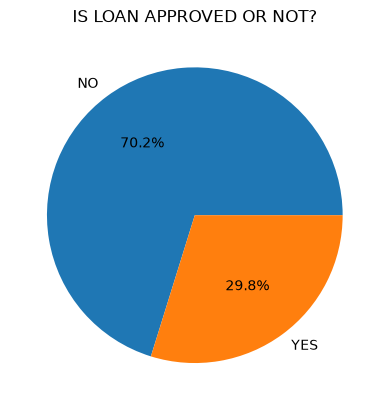

In [8]:
# how balance our classes are?
classes_count =  df["Loan_Approved"].value_counts()
plt.pie(classes_count,labels=["NO","YES"],autopct="%1.1f%%")
plt.title("IS LOAN APPROVED OR NOT?")

[Text(0, 0, '515'), Text(0, 0, '213'), Text(0, 0, '182'), Text(0, 0, '90')]

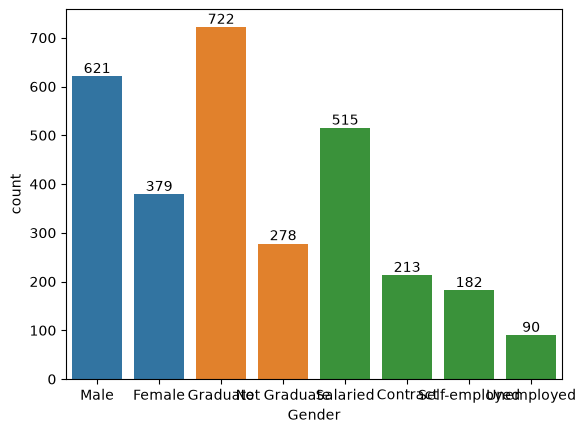

In [9]:
# analyze catogeries 
gender_cnt = df["Gender"].value_counts()
ax = sns.barplot(gender_cnt)
ax.bar_label(ax.containers[0])
edu_cnt = df["Education_Level"].value_counts()
bx = sns.barplot(edu_cnt)
bx.bar_label(bx.containers[1])
employement_cnt = df["Employment_Status"].value_counts()
cx= sns.barplot(employement_cnt)
cx.bar_label(cx.containers[2])

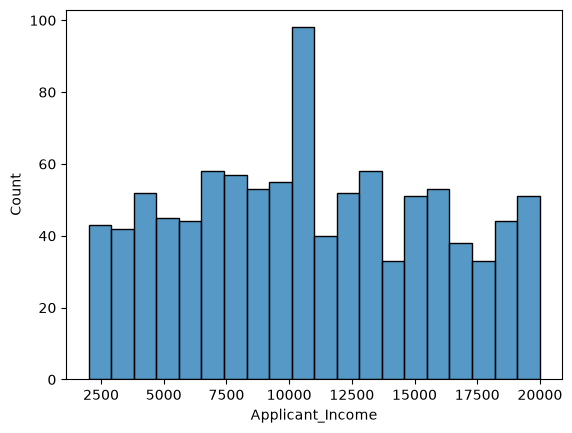

In [10]:
# analyze income
applicant_inc =sns.histplot(
    data = df,
    x = "Applicant_Income",
    bins = 20
)

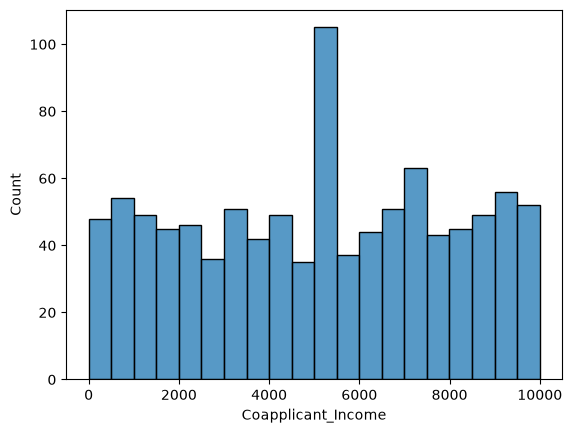

In [11]:
coapplicant_inc = sns.histplot(
    data = df,
    x = "Coapplicant_Income",
    bins = 20
)

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

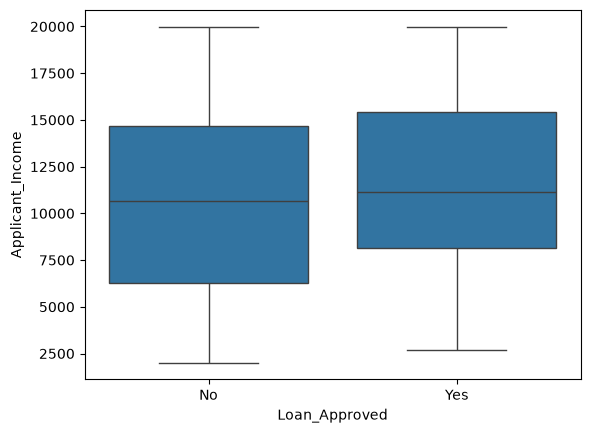

In [12]:
# outliers - box plot 
sns.boxplot(
    data= df,
    x = "Loan_Approved",
    y = "Applicant_Income"
)

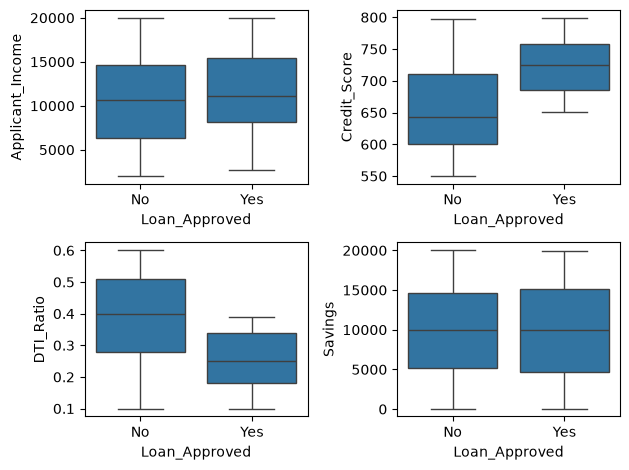

In [13]:
fig, axes = plt.subplots(2,2)
sns.boxplot(ax=axes[0,0],data = df,x = "Loan_Approved",y="Applicant_Income")
sns.boxplot(ax=axes[0,1],data = df,x = "Loan_Approved",y="Credit_Score")
sns.boxplot(ax=axes[1,0],data = df,x = "Loan_Approved",y="DTI_Ratio")
sns.boxplot(ax=axes[1,1],data = df,x = "Loan_Approved",y="Savings")
plt.tight_layout()

<Axes: xlabel='Credit_Score', ylabel='Count'>

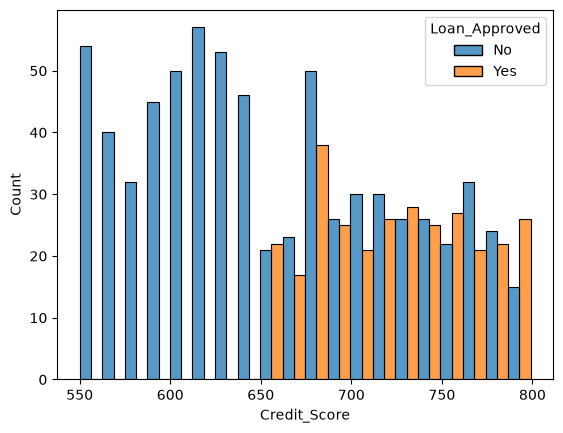

In [14]:
# credit score with loan approved
sns.histplot(
    data = df ,
    x= "Credit_Score",
    bins = 20,
    hue ="Loan_Approved",
    multiple = "dodge"
)

<Axes: xlabel='Applicant_Income', ylabel='Count'>

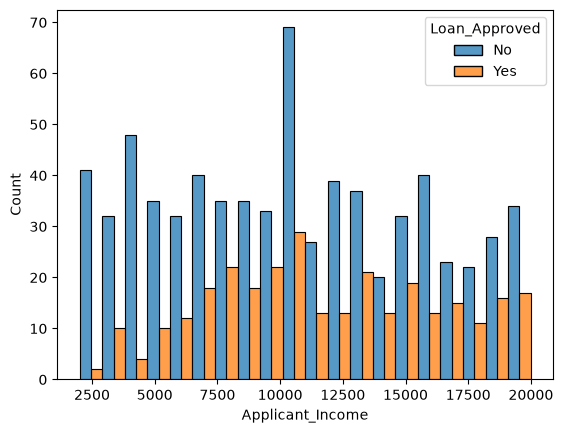

In [15]:
sns.histplot(
    data = df,
    x = "Applicant_Income",
    bins = 20,
    hue = "Loan_Approved",
    
    multiple = "dodge"
)

In [16]:
# Remove the Applicant ID
df= df.drop("Applicant_ID",axis = 1)

# ENCODING


In [17]:
df.columns
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_Income    1000 non-null   float64
 1   Coapplicant_Income  1000 non-null   float64
 2   Employment_Status   1000 non-null   str    
 3   Age                 1000 non-null   float64
 4   Marital_Status      1000 non-null   str    
 5   Dependents          1000 non-null   float64
 6   Credit_Score        1000 non-null   float64
 7   Existing_Loans      1000 non-null   float64
 8   DTI_Ratio           1000 non-null   float64
 9   Savings             1000 non-null   float64
 10  Collateral_Value    1000 non-null   float64
 11  Loan_Amount         1000 non-null   float64
 12  Loan_Term           1000 non-null   float64
 13  Loan_Purpose        1000 non-null   str    
 14  Property_Area       1000 non-null   str    
 15  Education_Level     1000 non-null   str    
 16  Gender            

In [18]:
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
le = LabelEncoder()
df["Education_Level"] = le.fit_transform(df["Education_Level"])
df["Loan_Approved"] = le.fit_transform(df["Loan_Approved"])



In [19]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,1,Female,Private,0
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,0,Male,Private,0
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,0,Female,Government,1
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,0,Female,Government,0
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,0,Male,Private,1


In [20]:
cols = ["Employment_Status","Marital_Status","Loan_Purpose","Gender","Employer_Category"]
ohe = OneHotEncoder(drop = "first",sparse_output = False,handle_unknown = "ignore")
encoded= ohe.fit_transform(df[cols])
encoded_df = pd.DataFrame(encoded,columns=ohe.get_feature_names_out(cols),index= df.index)
df = pd.concat([df.drop(columns = cols),encoded_df],axis=1)

In [21]:
df.head()
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 27 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_Income                 1000 non-null   float64
 1   Coapplicant_Income               1000 non-null   float64
 2   Age                              1000 non-null   float64
 3   Dependents                       1000 non-null   float64
 4   Credit_Score                     1000 non-null   float64
 5   Existing_Loans                   1000 non-null   float64
 6   DTI_Ratio                        1000 non-null   float64
 7   Savings                          1000 non-null   float64
 8   Collateral_Value                 1000 non-null   float64
 9   Loan_Amount                      1000 non-null   float64
 10  Loan_Term                        1000 non-null   float64
 11  Property_Area                    1000 non-null   str    
 12  Education_Level                 

# CORRELATION HEATMAP

<Axes: >

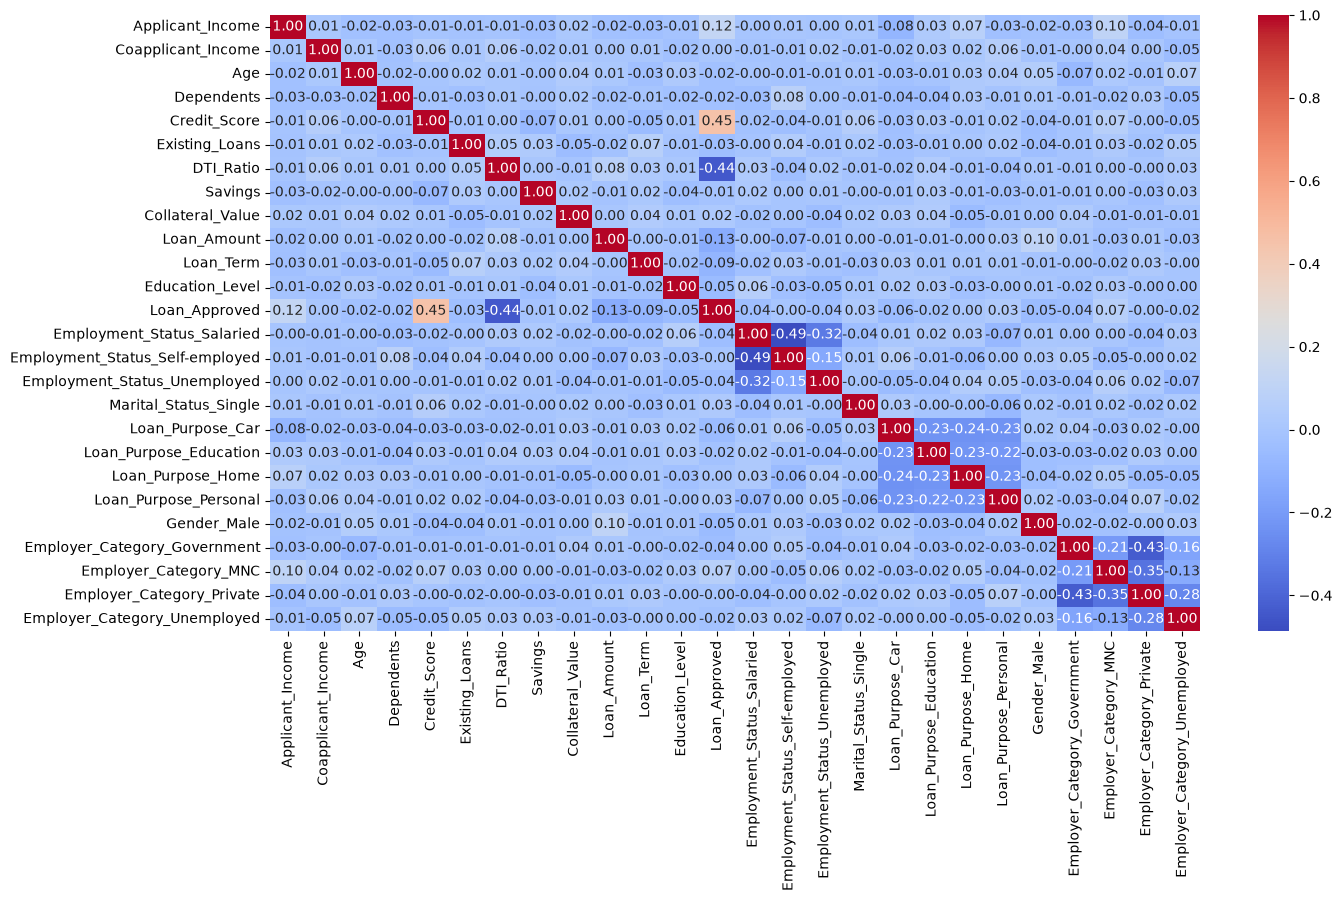

In [22]:
num_cols = df.select_dtypes(include = "number")
corr_matrix = num_cols.corr() 
plt.figure(figsize = (15,8))
sns.heatmap(
    corr_matrix,
    annot = True,
    fmt=".2f",
    cmap="coolwarm"
)

In [23]:
num_cols.corr()["Loan_Approved"].sort_values(ascending=False)

Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed      -0.044464
Education_Level                   -0.052920
Gender_Male                       -0.054342
Loan_Purpose_Car                

# TRAIN TEST SPLIT

In [24]:
X = df.drop("Loan_Approved",axis = 1)
y = df["Loan_Approved"]

In [25]:
X.head()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Marital_Status_Single,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.0,1387.0,51.0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,2860.0,2679.0,46.0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,7390.0,2106.0,25.0,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,13964.0,8173.0,40.0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,13284.0,4223.0,31.0,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,...,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [35]:
X_train,X_test,y_train,y_test =train_test_split(X,y,test_size = 0.2,random_state = 42)

In [36]:
X_train['Property_Area'] = X_train['Property_Area'].map({
    'Rural': 0,
    'Semiurban': 1,
    'Urban': 2
}).astype('float64')

X_test['Property_Area'] = X_test['Property_Area'].map({
    'Rural': 0,
    'Semiurban': 1,
    'Urban': 2
}).astype('float64')

In [37]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [38]:
X_train_scaled

array([[-1.01234556e+00,  1.02716377e+00, -8.22511453e-01, ...,
        -4.13887756e-01, -8.59726954e-01, -3.07231582e-01],
       [-1.23639141e+00, -1.59187898e+00,  9.15886794e-01, ...,
        -4.13887756e-01, -8.59726954e-01, -3.07231582e-01],
       [-1.15862490e-02,  1.33606578e+00, -3.65038230e-01, ...,
        -4.13887756e-01,  1.16316000e+00, -3.07231582e-01],
       ...,
       [-2.27277589e-01,  3.50089621e-01, -8.22511453e-01, ...,
        -4.13887756e-01,  1.16316000e+00, -3.07231582e-01],
       [ 1.12970221e+00, -4.64700438e-01,  1.19037073e+00, ...,
        -4.13887756e-01, -8.59726954e-01, -3.07231582e-01],
       [-1.75526629e+00,  1.43417276e-02,  9.40348249e-04, ...,
         2.41611400e+00, -8.59726954e-01, -3.07231582e-01]],
      shape=(800, 26))

# Train & EVALUATE MODEL

In [39]:
# Logistic regression 
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score,precision_score,recall_score,f1_score 
log_model = LogisticRegression()
log_model.fit(X_train_scaled,y_train)
y_pred =log_model.predict(X_test_scaled)
#Evaluation
print("precision : ", precision_score(y_test,y_pred))
print("accuracy : ", precision_score(y_test,y_pred))
print(" recall: ", recall_score(y_test,y_pred))
print("f1_score : ", f1_score(y_test,y_pred))
print("CM : ", confusion_matrix(y_test,y_pred))

precision :  0.7966101694915254
accuracy :  0.7966101694915254
 recall:  0.7704918032786885
f1_score :  0.7833333333333333
CM :  [[127  12]
 [ 14  47]]


In [42]:
# KNN
from sklearn.neighbors import KNeighborsClassifier 
knn_model = KNeighborsClassifier(n_neighbors = 5)
knn_model.fit(X_train_scaled,y_train)
y_pred =knn_model.predict(X_test_scaled)
#Evaluation
print("KNN model performance :- ") 
print("precision : ", precision_score(y_test,y_pred))
print("accuracy : ", precision_score(y_test,y_pred))
print(" recall: ", recall_score(y_test,y_pred))
print("f1_score : ", f1_score(y_test,y_pred))
print("CM : ", confusion_matrix(y_test,y_pred))

KNN model performance :- 
precision :  0.6808510638297872
accuracy :  0.6808510638297872
 recall:  0.5245901639344263
f1_score :  0.5925925925925926
CM :  [[124  15]
 [ 29  32]]


In [44]:
# naive bayes
from sklearn.naive_bayes import GaussianNB 
nb_model = GaussianNB() 
nb_model.fit(X_train_scaled,y_train)
y_pred = nb_model.predict(X_test_scaled)
#Evaluation
print("KNN model performance :- ") 
print("precision : ", precision_score(y_test,y_pred))
print("accuracy : ", precision_score(y_test,y_pred))
print("recall: ", recall_score(y_test,y_pred))
print("f1_score : ", f1_score(y_test,y_pred))
print("CM : ", confusion_matrix(y_test,y_pred))

KNN model performance :- 
precision :  0.7966101694915254
accuracy :  0.7966101694915254
recall:  0.7704918032786885
f1_score :  0.7833333333333333
CM :  [[127  12]
 [ 14  47]]


# FEATURE ENGINEERING 

In [55]:
# ADD or transform features 
df["DTI_Ratio_sq"]=df["DTI_Ratio"]**2
df["Credit_Score_sq"] = df["Credit_Score"]**2
# df["Applicant_Income_log"] = np.log1p(df["Applicant_Income"])
X = df.drop(columns = ["Loan_Approved","Credit_Score","DTI_Ratio"])
y = df["Loan_Approved"]
# train test split
X = pd.get_dummies(X, columns=['Property_Area'], drop_first=True, dtype=int)
X_train,X_test,y_train,y_test =train_test_split(X,y,test_size = 0.2,random_state = 42)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [56]:
# Logistic regression 
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score,precision_score,recall_score,f1_score 
log_model = LogisticRegression()
log_model.fit(X_train_scaled,y_train)
y_pred =log_model.predict(X_test_scaled)
#Evaluation
print("precision : ", precision_score(y_test,y_pred))
print("accuracy : ", precision_score(y_test,y_pred))
print(" recall: ", recall_score(y_test,y_pred))
print("f1_score : ", f1_score(y_test,y_pred))
print("CM : ", confusion_matrix(y_test,y_pred))

precision :  0.7846153846153846
accuracy :  0.7846153846153846
 recall:  0.8360655737704918
f1_score :  0.8095238095238095
CM :  [[125  14]
 [ 10  51]]


In [57]:
# KNN
from sklearn.neighbors import KNeighborsClassifier 
knn_model = KNeighborsClassifier(n_neighbors = 5)
knn_model.fit(X_train_scaled,y_train)
y_pred =knn_model.predict(X_test_scaled)
#Evaluation
print("KNN model performance :- ") 
print("precision : ", precision_score(y_test,y_pred))
print("accuracy : ", precision_score(y_test,y_pred))
print(" recall: ", recall_score(y_test,y_pred))
print("f1_score : ", f1_score(y_test,y_pred))
print("CM : ", confusion_matrix(y_test,y_pred))

KNN model performance :- 
precision :  0.6730769230769231
accuracy :  0.6730769230769231
 recall:  0.5737704918032787
f1_score :  0.6194690265486725
CM :  [[122  17]
 [ 26  35]]


In [59]:
# naive bayes
from sklearn.naive_bayes import GaussianNB 
nb_model = GaussianNB() 
nb_model.fit(X_train_scaled,y_train)
y_pred = nb_model.predict(X_test_scaled)
#Evaluation
print("KNN model performance :- ") 
print("precision : ", precision_score(y_test,y_pred))
print("accuracy : ", precision_score(y_test,y_pred))
print("recall: ", recall_score(y_test,y_pred))
print("f1_score : ", f1_score(y_test,y_pred))
print("CM : ", confusion_matrix(y_test,y_pred))

KNN model performance :- 
precision :  0.8113207547169812
accuracy :  0.8113207547169812
recall:  0.7049180327868853
f1_score :  0.7543859649122807
CM :  [[129  10]
 [ 18  43]]
